# 🖼️ Image Processing Utility Suite - User Guide

Welcome to the Image Analyzer! This application provides a full Desktop Graphical User Interface (GUI) allowing you to process, manipulate, and export photos quickly without writing any code.

## 🚀 How to Launch the Application

Ensure you are inside the `Image-Analyzer` folder in your terminal, and simply run the launcher command:
```bash
python main.py
```
A standalone desktop application window will immediately pop up on your screen.

## 🛠️ Features Breakdown

### 1. Load your Media
*   **Open Image:** Click the top button to open a file explorer. Select any photo (`.jpg`, `.png`, etc.) from your computer. The image will instantly preview on the right-hand canvas.

### 2. Enhancements (OpenCV Tools)
*   **Apply Grayscale:** Instantly strips the color channels, converting your image entirely to crisp black and white.
*   **Edge Detection:** Extracts the boundary edges of subjects in the photo. Internally, the app applies a Gaussian Blur to reduce background noise, then runs a Canny Edge algorithm to create a striking sketch/outline effect.

### 3. Utilities & Exporting
*   **Add Watermark:** Fuses a semi-transparent white `PROPERTY OF AUTHOR` watermark directly into the center of the image. The algorithm automatically scales the text size relative to your image's original dimensions!
*   **Save Image:** Exports your newly modified image (with all effects applied) back to your hard drive as a high-quality `.png` or `.jpg` file.
*   **Export to PDF:** Need to share the image formally? This completely converts the current state of the image into a clean `.pdf` document via the Python Imaging Library.

## 💻 Code Examples

Below are runnable examples demonstrating the same image-processing operations the GUI performs under the hood. Run these cells in order to see each feature in action.

In [1]:
import cv2
import numpy as np
from PIL import Image
import os
import matplotlib.pyplot as plt

# Helper to display images inline (BGR -> RGB for correct colors)
def show(title, img):
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(6, 4))
    plt.imshow(rgb)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

### 1. Load an Image

The GUI uses `cv2.imread()` to load any `.jpg`, `.png`, or `.bmp` file.

Generated sample image -> sample.jpg
Loaded image shape: (400, 600, 3)


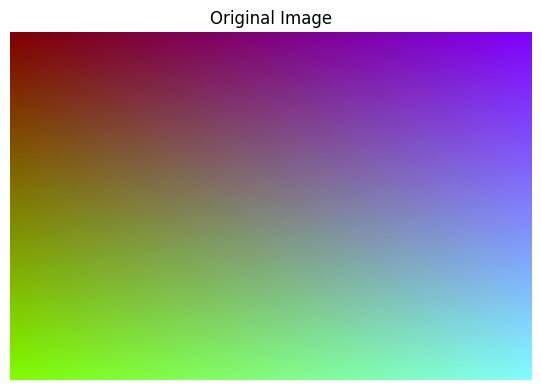

In [2]:
# Load an image from disk (replace with your own file path)
sample_path = "sample.jpg"   # place any image here

if not os.path.exists(sample_path):
    # Generate a sample image so the notebook is self-contained
    img = np.zeros((400, 600, 3), dtype=np.uint8)
    for i in range(400):
        for j in range(600):
            img[i, j] = [int(255 * j / 600), int(255 * i / 400), 128]
    cv2.imwrite(sample_path, img)
    print(f"Generated sample image -> {sample_path}")

img = cv2.imread(sample_path)
print(f"Loaded image shape: {img.shape}")
show("Original Image", img)

### 2. Apply Grayscale

Strips the color channels and converts the image to black and white.

Grayscale shape: (400, 600, 3)


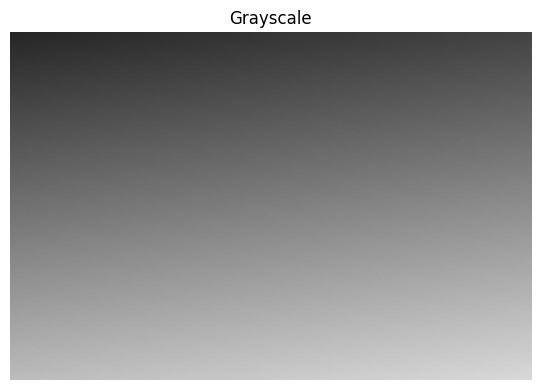

In [3]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray_bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)

print(f"Grayscale shape: {gray_bgr.shape}")
show("Grayscale", gray_bgr)

### 3. Edge Detection

Applies a Gaussian Blur to reduce noise, then runs the Canny Edge algorithm.

Edge-detected shape: (400, 600, 3)


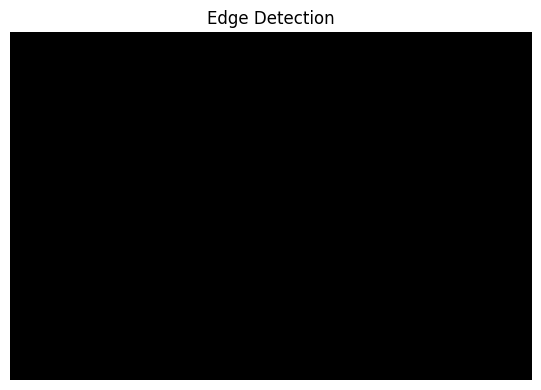

In [4]:
gray_for_edges = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray_for_edges, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150)
edges_bgr = cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

print(f"Edge-detected shape: {edges_bgr.shape}")
show("Edge Detection", edges_bgr)

### 4. Add Watermark

Fuses a semi-transparent white `PROPERTY OF AUTHOR` watermark into the center, scaled to the image dimensions.

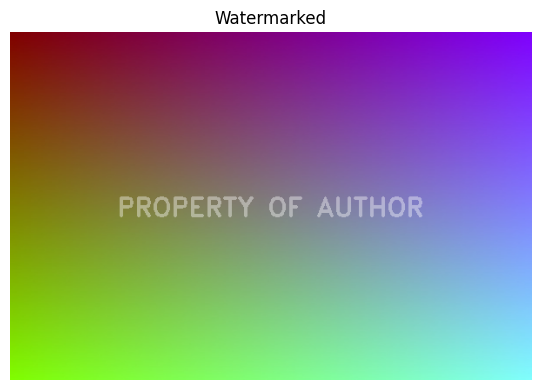

In [5]:
watermarked = img.copy()
text = "PROPERTY OF AUTHOR"
color = (255, 255, 255)
font = cv2.FONT_HERSHEY_DUPLEX

height, width = watermarked.shape[:2]
scale = width / 600.0
thickness = int(max(1, scale * 2))

text_size = cv2.getTextSize(text, font, scale, thickness)[0]
text_x = int((width - text_size[0]) / 2)
text_y = int((height + text_size[1]) / 2)

overlay = watermarked.copy()
cv2.putText(overlay, text, (text_x, text_y), font, scale, color, thickness)
cv2.addWeighted(overlay, 0.4, watermarked, 0.6, 0, watermarked)

show("Watermarked", watermarked)

### 5. Save Image

Exports the modified image as `.png` or `.jpg`.

In [6]:
save_path = "output.png"
cv2.imwrite(save_path, watermarked)
print(f"Saved to {save_path} ({os.path.getsize(save_path)} bytes)")

Saved to output.png (113918 bytes)


### 6. Export to PDF

Converts the image into a `.pdf` document via the Python Imaging Library.

In [7]:
pdf_path = "output.pdf"
rgb_image = cv2.cvtColor(watermarked, cv2.COLOR_BGR2RGB)
pil_img = Image.fromarray(rgb_image)
pil_img.save(pdf_path, "PDF", resolution=100.0)
print(f"Exported to {pdf_path} ({os.path.getsize(pdf_path)} bytes)")

Exported to output.pdf (12234 bytes)


---

All examples above mirror the exact operations performed by the GUI buttons in `main.py`. To use the full desktop application instead, run:
```bash
python main.py
```